In [43]:
import os
import seaborn as sns

In [44]:
from google.colab import userdata
token = userdata.get('hm2')
os.environ["KAGGLE_API_TOKEN"] = token

In [45]:
from pathlib import Path
if not Path('/content/data/train').exists():
    !kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content/data
    !cd /content/data && unzip -q '*.zip' && rm *.zip
else:
    print('Data is already here')
!ls /content/data

Data is already here
multiple-object-video-detection-hw-2-ucu-ai-2026.zip  test_images.csv  val
test						      train


Data structure:

In [46]:
from pathlib import Path
ROOT = Path('/content/data')

for split in ['train', 'val', 'test']:
    d = ROOT / split
    clips = sorted(p.name for p in (d / 'images').iterdir())
    n_img = sum(1 for _ in (d / 'images').rglob('*.jpg'))
    n_ign = sum(1 for _ in (d / 'ignore').rglob('*.txt')) if (d / 'ignore').exists() else 0
    print(f'{split}: {len(clips)} clips, {n_img} кадрів, {n_ign} frames in ignore;')

print("\ntrain/data.yaml:")
print(open(ROOT / 'train/data.yaml').read())

print("\nval/data.yaml:")
print(open(ROOT / 'val/data.yaml').read())

train: 56 clips, 24201 кадрів, 18090 frames in ignore;
val: 7 clips, 2846 кадрів, 1434 frames in ignore;
test: 48 clips, 3811 кадрів, 0 frames in ignore;

train/data.yaml:
path: .
train: images
val: images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


val/data.yaml:
path: .
train: images
val: images
nc: 8
names: ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]



Downloading COCO

In [47]:
import json, numpy as np, pandas as pd
CLASSES = ['person','bicycle','car','van','truck','tricycle','bus','motor']

def load(split):
    coco = json.load(open(ROOT / split / 'annotations_coco.json'))
    imgs = pd.DataFrame(coco['images']).rename(columns={'id': 'image_id'})
    # назва кліпу: колонка 'video', або папка з file_name
    if 'video' not in imgs.columns:
        imgs['video'] = imgs['file_name'].map(lambda p: Path(p).parent.name)
    anns = pd.DataFrame(coco['annotations'])
    anns[['x', 'y', 'w', 'h']] = pd.DataFrame(anns['bbox'].tolist(), index=anns.index)
    anns['cls'] = anns['category_id'] - 1            # 0-based, як у YOLO і сабміті
    if 'iscrowd' not in anns.columns:
        anns['iscrowd'] = 0
    anns = anns.merge(imgs[['image_id', 'video', 'width', 'height']], on='image_id')
    anns['split'] = split
    imgs['split'] = split
    return coco, imgs, anns

coco_tr, imgs_tr, anns_tr = load('train')
coco_va, imgs_va, anns_va = load('val')

print(coco_tr['categories'])
print('\nColums images:', list(imgs_tr.columns))
print(imgs_tr.head(3))
print('\nColums annotations:', list(anns_tr.columns))
print(anns_tr.head(3))

[{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]

Colums images: ['image_id', 'file_name', 'width', 'height', 'video_id', 'video', 'frame_id', 'split']
   image_id                              file_name  width  height  video_id  \
0         1  images/uav0000013_00000_v/0000001.jpg   1344     756         1   
1         2  images/uav0000013_00000_v/0000002.jpg   1344     756         1   
2         3  images/uav0000013_00000_v/0000003.jpg   1344     756         1   

                video  frame_id  split  
0  uav0000013_00000_v         1  train  
1  uav0000013_00000_v         2  train  
2  uav0000013_00000_v         3  train  

Colums annotations: ['id', 'image_id', 'category_id', 'bbox', 'area', 'iscrowd', 'truncation', 'occlusion', 'track_id', 'orig_category_id', 'ignore', 'x', 'y', 'w', 'h', 'cls', 'video', 'wid

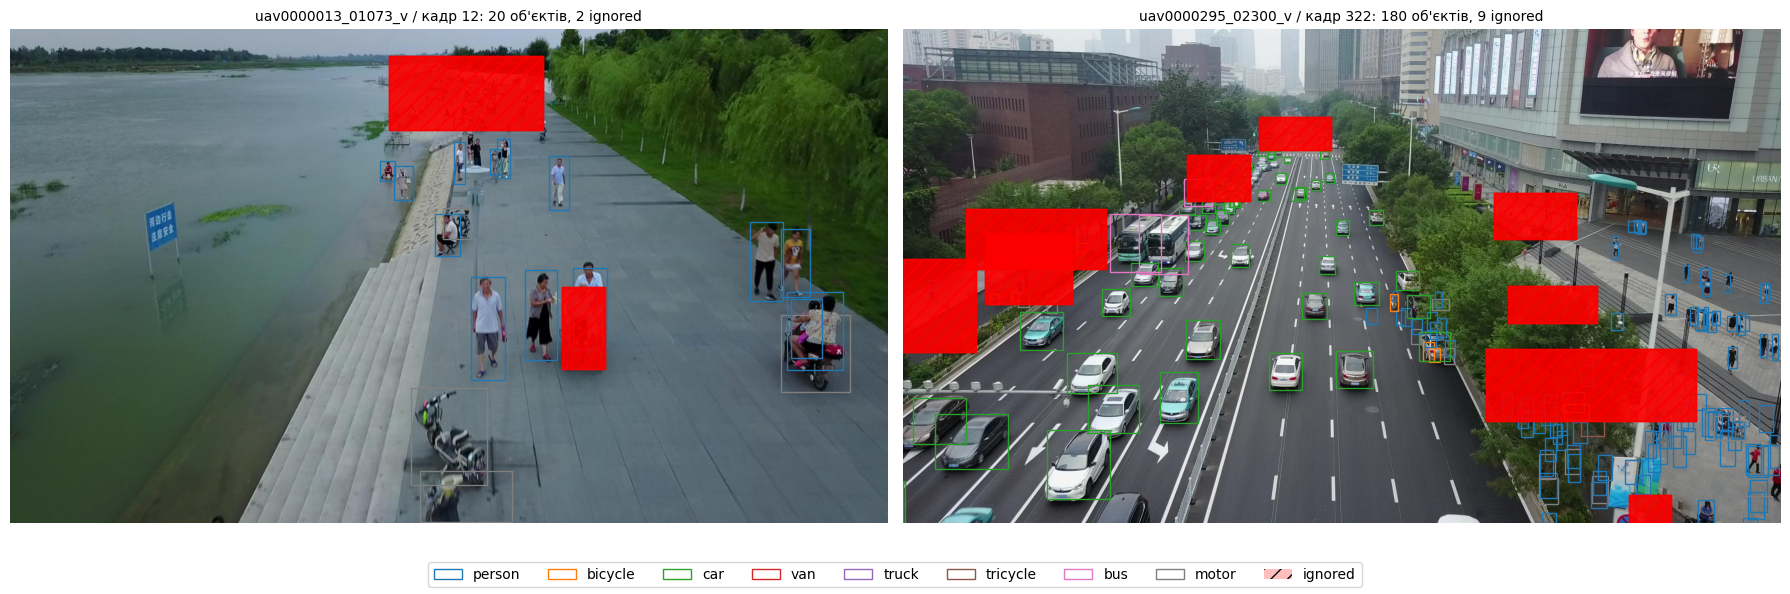

In [79]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

COLORS = plt.cm.tab10(range(8))

def show_frame(image_id, split='train', ax=None, zoom=None):
    im_df, an_df = (imgs_tr, anns_tr) if split == 'train' else (imgs_va, anns_va)
    info = im_df[im_df.image_id == image_id].iloc[0]
    a = an_df[an_df.image_id == image_id]
    ax = ax or plt.subplots(figsize=(14, 8))[1]
    ax.imshow(Image.open(ROOT / split / info.file_name))
    for r in a.itertuples():
        if r.iscrowd:   # ignored region
            ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fc='red', alpha=.25, ec='red', hatch='//'))
        else:
            ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, lw=1, ec=COLORS[r.cls]))
    if zoom:
        x, y, w, h = zoom
        ax.set_xlim(x, x + w); ax.set_ylim(y + h, y)
    n_obj, n_ign = (a.iscrowd == 0).sum(), (a.iscrowd == 1).sum() // 8
    ax.set_title(f'{info.video} / кадр {info.frame_id}: {n_obj} об\'єктів, {n_ign} ignored', fontsize=10)
    ax.set_axis_off()
    return ax

legend = [patches.Patch(ec=COLORS[i], fill=False, label=c) for i, c in enumerate(CLASSES)]
legend.append(patches.Patch(fc='red', alpha=.25, hatch='//', label='ignored'))

n_obj = anns_tr[anns_tr.iscrowd == 0].groupby('image_id').size()
sparse_id = n_obj[n_obj.between(10, 20)].index[0]
dense_id = n_obj.idxmax()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
show_frame(sparse_id, ax=axes[0])
show_frame(dense_id, ax=axes[1])
fig.legend(handles=legend, loc='lower center', ncol=9)
plt.tight_layout(rect=[0, .05, 1, 1]); plt.savefig('gt_examples.png', dpi=120); plt.show()

Class distribution

In [49]:
anns = pd.concat([anns_tr, anns_va], ignore_index=True)
imgs = pd.concat([imgs_tr, imgs_va], ignore_index=True)
obj = anns[anns['iscrowd'] == 0]
ign = anns[anns['iscrowd'] == 1]

print("Objects:", obj.groupby('split').size().to_dict())
print('Ignored regions:', ign.groupby('split').size().to_dict())

dist = obj.groupby(['cls', 'split']).size().unstack('split').fillna(0)
dist.index = [CLASSES[int(i)] for i in dist.index]
print('\Classes, %:\n', (dist / dist.sum() * 100).round(1))

print('\nResolutions:\n', imgs.groupby(['split', 'width', 'height']).size())

<>:11: SyntaxWarning: invalid escape sequence '\C'
<>:11: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipykernel_704/70359528.py:11: SyntaxWarning: invalid escape sequence '\C'
  print('\Classes, %:\n', (dist / dist.sum() * 100).round(1))


Objects: {'train': 1105516, 'val': 114132}
Ignored regions: {'train': 510744, 'val': 31960}
\Classes, %:
 split     train   val
person     29.7  44.1
bicycle     3.6   5.3
car        45.7  27.9
van         4.2   6.0
truck       2.8   1.2
tricycle    3.7   4.8
bus         0.9   0.2
motor       9.3  10.5

Resolutions:
 split  width  height
train  1344   756        5645
       1360   765         962
       1904   1071      12895
       1920   1080        721
       2688   1512       3505
       2720   1530        473
val    1344   756         827
       1904   1071        459
       2688   1512        233
       2720   1530        349
       3840   2160        978
dtype: int64


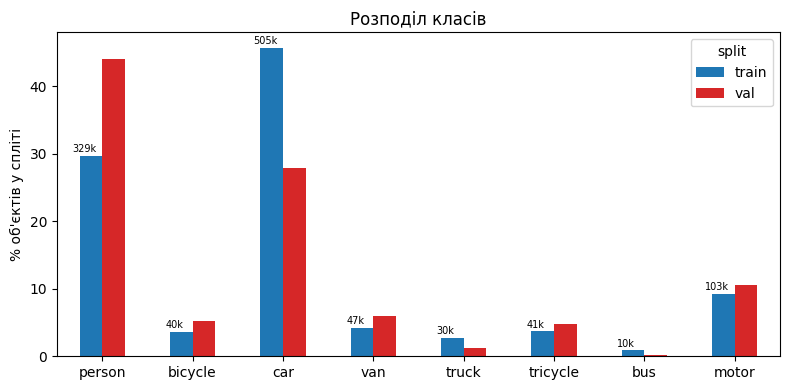

In [50]:
cnt = obj.groupby(['cls', 'split']).size().unstack()
cnt.index = CLASSES
pct = cnt / cnt.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))
pct.plot(kind='bar', ax=ax, color=['tab:blue', 'tab:red'])
for i, v in enumerate(cnt['train']):
    ax.text(i - .2, pct['train'].iloc[i] + .5, f'{v/1000:.0f}k', ha='center', fontsize=7)
ax.set_ylabel('% об\'єктів у спліті')
ax.set_title('Розподіл класів')

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('cls_overall.png', dpi=120)
plt.show()

In [51]:
OCC_NAMES = {0: 'no occ', 1: 'partial occ', 2: 'heavy occ'}
OCC_ORDER = [2, 1, 0]                       # heavy on the left
splits = sorted(obj['split'].unique(), key=lambda s: s != 'train')   # train first

# share of objects with a valid occlusion value
valid = obj['occlusion'].isin(OCC_NAMES.keys())
cov = pd.DataFrame({
    'objects': obj.groupby('split').size(),
    'with occlusion': valid.groupby(obj['split']).sum(),
})
cov['%'] = (cov['with occlusion'] / cov['objects'] * 100).round(2)
print('Occlusion field coverage:\n', cov.loc[splits], '\n')

# counts per class x occlusion level, per split
occ_obj = obj[valid]
tab = (occ_obj.groupby(['split', 'cls', 'occlusion']).size()
              .unstack('occlusion', fill_value=0)
              .reindex(columns=OCC_ORDER, fill_value=0)
              .rename(columns=OCC_NAMES))

counts = {}
for s in splits:
    t = tab.loc[s].reindex(range(len(CLASSES)), fill_value=0)
    t.index = CLASSES
    t['total'] = t.sum(axis=1)
    counts[s] = t                                   # raw counts, used by the plot

    occ_cols = [OCC_NAMES[o] for o in OCC_ORDER]
    p = t[occ_cols].div(t['total'], axis=0) * 100   # occlusion mix within each class
    p['% of split'] = t['total'] / t['total'].sum() * 100
    print(f'{s}, %:\n{p.round(1)}\n')

Occlusion field coverage:
        objects  with occlusion      %
split                                
train  1105516         1105516  100.0
val     114132          114132  100.0 

train, %:
occlusion  heavy occ  partial occ  no occ  % of split
person           6.3         39.6    54.1        29.7
bicycle          3.4         50.1    46.5         3.6
car              4.6         38.4    57.0        45.7
van              2.5         40.4    57.1         4.2
truck           15.8         48.9    35.3         2.8
tricycle         2.1         57.0    40.9         3.7
bus              2.1         42.0    55.9         0.9
motor            6.3         39.0    54.7         9.3

val, %:
occlusion  heavy occ  partial occ  no occ  % of split
person           4.7         49.4    45.9        44.1
bicycle          1.9         88.6     9.6         5.3
car              9.3         47.1    43.7        27.9
van             10.6         49.5    39.8         6.0
truck           10.9         71.0    18.1   

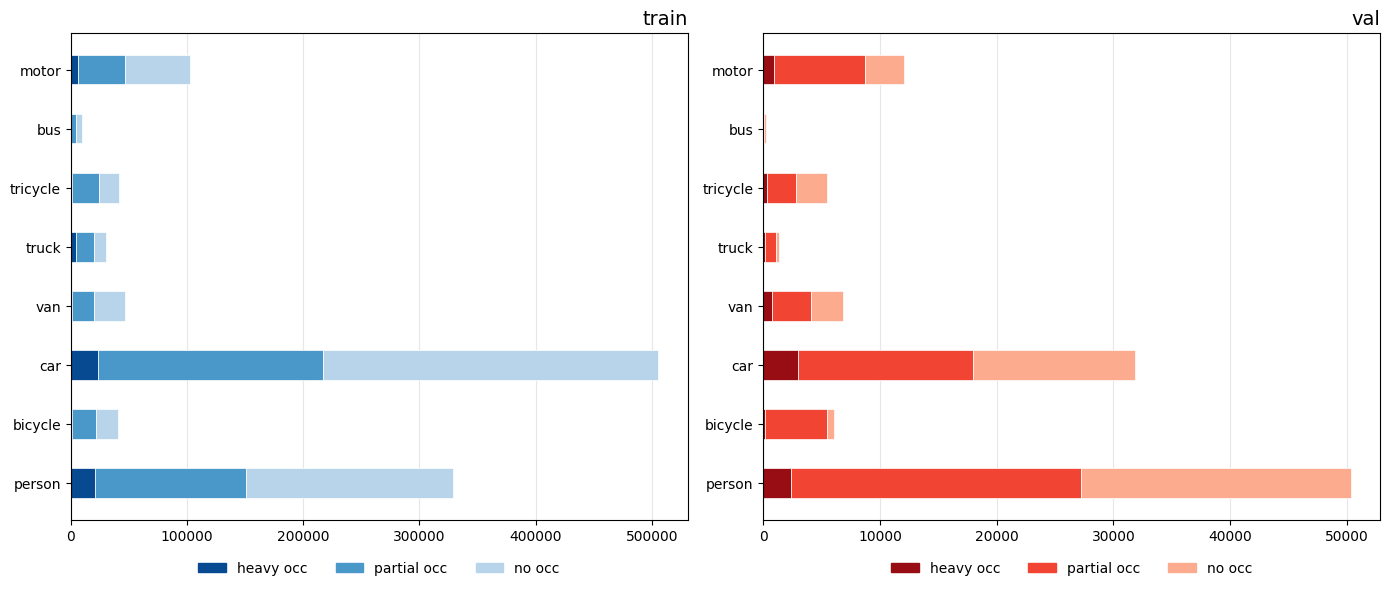

In [52]:
from matplotlib.patches import Patch

cmaps = {'train': plt.cm.Blues, 'val': plt.cm.Reds}

fig, axes = plt.subplots(1, len(splits), figsize=(7 * len(splits), 6))
axes = np.atleast_1d(axes)

for ax, s in zip(axes, splits):
    shades = dict(zip(['no occ', 'partial occ', 'heavy occ'],
                      cmaps.get(s, plt.cm.Greys)([0.3, 0.6, 0.9])))   # darker = heavier
    t = counts[s]
    left = np.zeros(len(t))
    for col in [OCC_NAMES[o] for o in OCC_ORDER]:
        ax.barh(t.index, t[col], left=left, height=0.5, color=shades[col],
                edgecolor='white', linewidth=0.5)
        left += t[col].values

    ax.set_title(s, loc='right', fontsize=14)
    ax.grid(axis='x', alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(handles=[Patch(color=shades[OCC_NAMES[o]], label=OCC_NAMES[o]) for o in OCC_ORDER],
              ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.06), frameon=False)

plt.tight_layout()
plt.savefig('cls_occlusion.png', dpi=120, bbox_inches='tight')
plt.show()

* Partial occlusion is common: 40–50% of objects. Heavy occlusion is rare, about 5%.
* Val is more occluded than train: about 41% of val objects are fully visible, versus about 54% in train.
* Truck is the most occluded class: 11–16% heavy occlusion, and only 18–35% fully visible.
* Bicycle and motor are mostly partially occluded in val (89% and 65%), probably by their riders.
* Car and van are more heavily occluded in val (9–11% vs 3–5% in train), which suggests denser traffic scenes.


Висновок по **class distribution**:

class imbalance issue is extremely severe in our dataset,

1. Класи домінують - **car**(45.7%), **person**(29.7%) - всього майже 75% всіх об`єктів.
2. Рідкісні класи - **bus**(0.9%), **truck**(2.8%), **bicycle**(3.6%), **tricycle**(3.7%), **van**(4.2%).
Різниця між найчастішим і найрідкіснішим класом майже в 50 разів -> дані сильно незбалансовані.
3. У train і val не пропорційно тих самих об`єктів(person - 29.7 vs 44.1) .

### Distribution of object sizes

Розмір об'єкта міряємо як sqrt(w*h) у пікселях. Межі беремо з COCO: small < 32 px, medium 32–96 px, large > 96 px. За ними рахується AP_small.

# TODO: **ПЕРЕПИСАТИ**

Частка small/medium/large і квантилі розмірів

In [53]:
obj = obj.copy()
obj['sqrt_area'] = np.sqrt(obj['w'] * obj['h'])
obj['size_cat'] = pd.cut(obj['w'] * obj['h'], [0, 32**2, 96**2, np.inf],
                         labels=['small', 'medium', 'large'], right=False)

print('Частка за COCO-розміром, %:\n',
      (obj.groupby('split')['size_cat'].value_counts(normalize=True) * 100).round(1).unstack())
print('\nsqrt(area), px (10%, медіана, 90%):\n',
      obj.groupby('split')['sqrt_area'].quantile([.1, .5, .9]).unstack().round(1))

Частка за COCO-розміром, %:
 size_cat  small  medium  large
split                         
train      24.9    63.5   11.6
val        19.2    69.5   11.3

sqrt(area), px (10%, медіана, 90%):
         0.1   0.5    0.9
split                   
train  24.0  45.8  101.6
val    26.1  52.4   99.3


1. У пікселях оригіналу більшість об'єктів medium; small only 25%,бо розміри кадру великі-> розміри об`єктів більші
2. Train і val схожі за розміром
3. Розкид розмірів великий


How to resize

In [54]:
# частка small після ресайзу кадру до imgsz по довшій стороні
long_side = obj[['width', 'height']].max(axis=1)
rows = {}
for imgsz in [640, 960, 1280, 1600]:
    s = obj['sqrt_area'] * np.minimum(imgsz / long_side, 1)
    rows[imgsz] = {'small, %': (s < 32).mean() * 100, '< 16 px, %': (s < 16).mean() * 100,
                   'медіана, px': s.median()}
print(pd.DataFrame(rows).T.round(1))

test = pd.read_csv(ROOT / 'test_images.csv')
print('\nРозміри тестових кадрів:\n', test.groupby(['width', 'height']).size())

      small, %  < 16 px, %  медіана, px
640       89.2        53.6         15.3
960       73.2        23.5         22.9
1280      53.6         9.7         30.6
1600      39.8         4.6         36.6

Розміри тестових кадрів:
 width  height
680    382        321
960    540        279
1344   756        441
1360   764       1474
1904   1072       305
1920   1080       991
dtype: int64


When imgsz=640 objects are too small - 89% are small and 53% are less than 16px - > model would not be able to зачепитися .


Choose 1280 as small is 54%, and smaller than 16 px ~10%, median ~ 31 px. 1600 is even better (4.6% < 16 px), but learning will be slower




Test кадри are smaller -> objects in test would be smaller in pixels-> use scale-augumentation.(suggestion)



# TODO: ^^^ check this ^^^

Гістограма розмірів

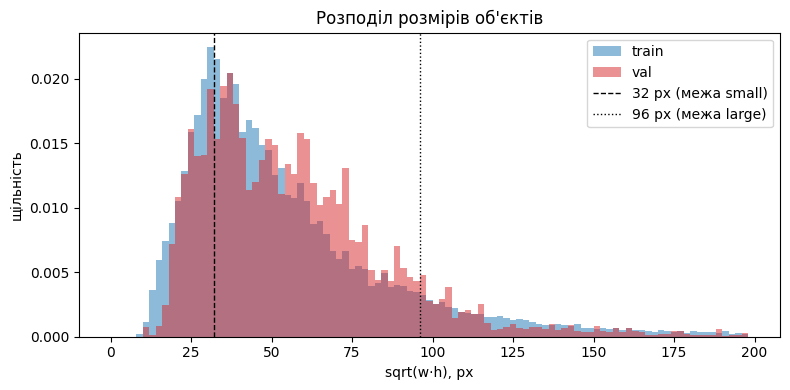

In [55]:
fig, ax = plt.subplots(figsize=(8, 4))
for s, c in [('train', 'tab:blue'), ('val', 'tab:red')]:
    ax.hist(obj.loc[obj.split == s, 'sqrt_area'], bins=np.arange(0, 200, 2),
            density=True, alpha=.5, color=c, label=s)
ax.axvline(32, c='k', ls='--', lw=1, label='32 px (межа small)')
ax.axvline(96, c='k', ls=':', lw=1, label='96 px (межа large)')
ax.set_xlabel('sqrt(w·h), px'); ax.set_ylabel('щільність')
ax.set_title('Розподіл розмірів об\'єктів'); ax.legend()
plt.tight_layout(); plt.savefig('size_hist.png', dpi=120); plt.show()

Skewned to the left, long tail >100

Розмір і форма за класом

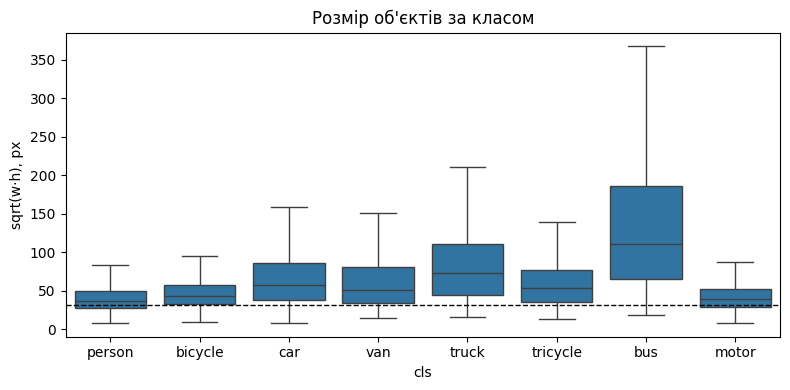

Медіанне h/w за класом: {'person': 2.0, 'bicycle': 1.08, 'car': 0.79, 'van': 0.88, 'truck': 0.93, 'tricycle': 0.95, 'bus': 0.96, 'motor': 1.24}


In [56]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=obj.sample(200_000, random_state=0), x='cls', y='sqrt_area',
            showfliers=False, color='tab:blue', ax=ax)
ax.axhline(32, c='k', ls='--', lw=1)
ax.set_xticks(range(8), CLASSES); ax.set_ylabel('sqrt(w·h), px')
ax.set_title('Розмір об\'єктів за класом')
plt.tight_layout(); plt.savefig('size_per_class.png', dpi=120); plt.show()

# співвідношення сторін h/w: знадобиться для якорів (anchors) у RetinaNet
obj['aspect'] = obj['h'] / obj['w']
print('Медіанне h/w за класом:',
      obj.groupby('cls')['aspect'].median().rename(dict(enumerate(CLASSES))).round(2).to_dict())

1. The smalest classes - person and motor (median ~35–40 px), but they are the most numerous-> AP_small will depend on them.
2. The biggest — bus і truck (median ~110 і ~75 px): rare classes are big -> їхня проблема в малій к-сті прикладів, а не в розмірі.
3. Розкид усередині класу великий (у bus від ~20 до ~370 px), бо дрон знімає з різної висоти -> multi-scale (FPN) і scale-аугментацію.
4. Person витягнутий вертикально (h/w = 2.0), motor трохи (1.24), решта майже квадратні або трохи ширші (car 0.79), -> для якорів RetinaNet треба взяти aspect ratios приблизно від 0.8 до 2.


Heavy-occluded buses in train: 202 | frames: 202


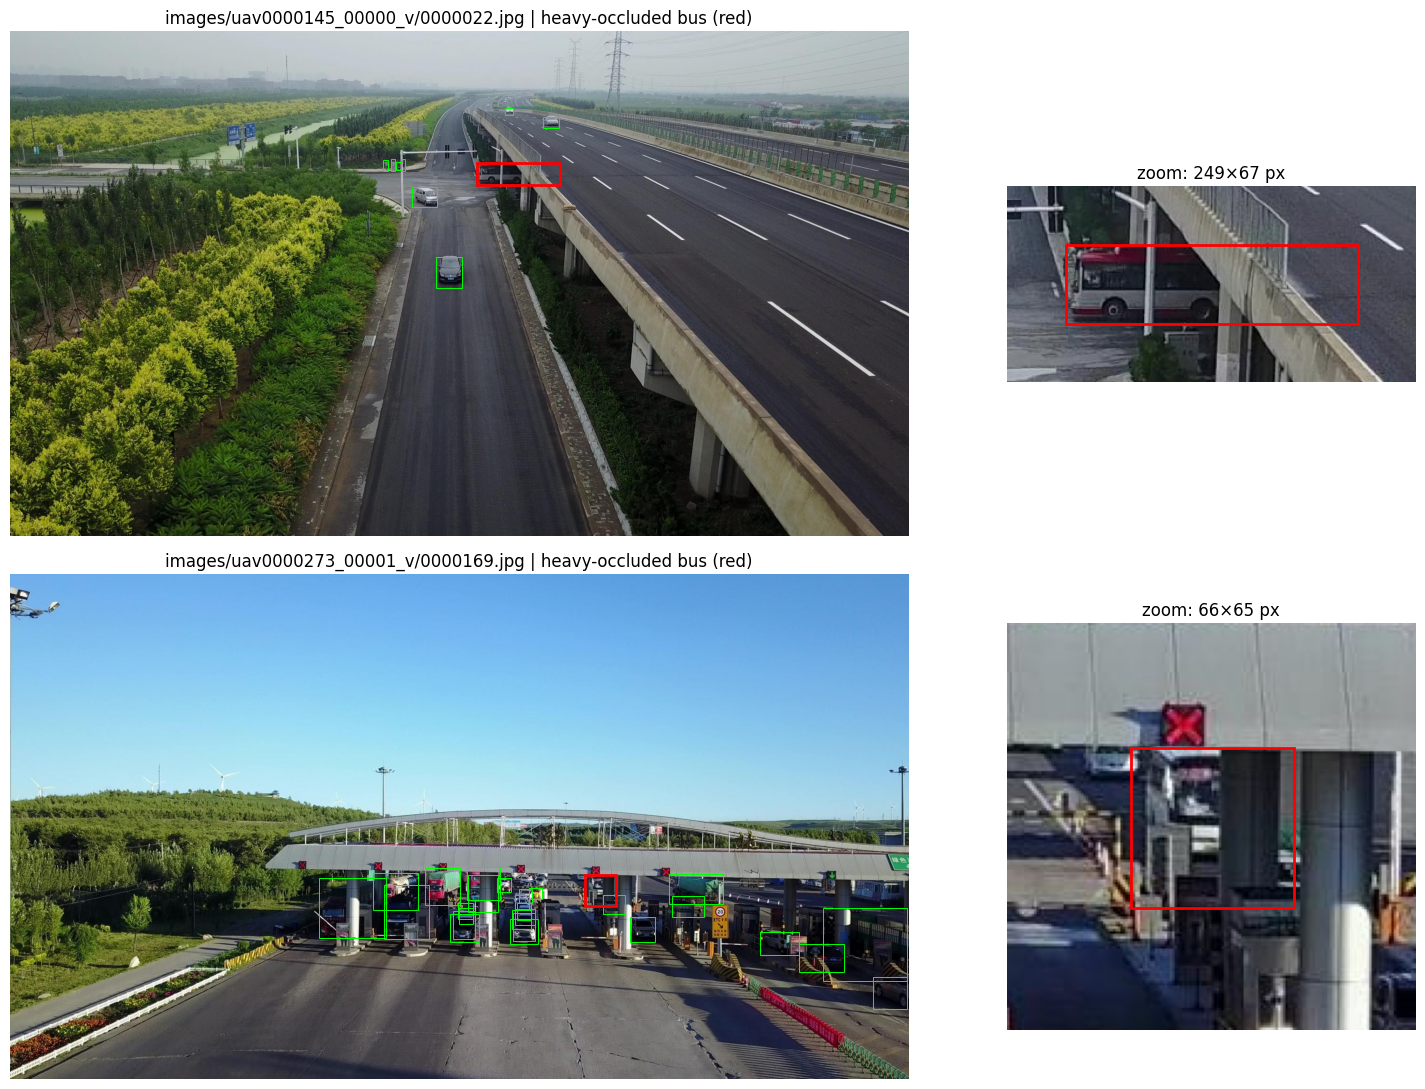

In [57]:
SEED_1 = 0
SEED_2 = 42

bus = CLASSES.index('bus')
cand = anns_tr[(anns_tr.iscrowd == 0) & (anns_tr.cls == bus) & (anns_tr.occlusion == 2)]
print('Heavy-occluded buses in train:', len(cand), '| frames:', cand.image_id.nunique())

def show_bus(r, ax_full, ax_zoom, pad=50):
    info = imgs_tr[imgs_tr.image_id == r.image_id].iloc[0]
    im = Image.open(ROOT / 'train' / info.file_name)
    others = anns_tr[(anns_tr.image_id == r.image_id) & (anns_tr.iscrowd == 0)]

    ax_full.imshow(im)
    for o in others.itertuples():
        ax_full.add_patch(patches.Rectangle((o.x, o.y), o.w, o.h, fill=False, ec='lime', lw=0.7))
    ax_full.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, ec='red', lw=2))
    ax_full.set_title(f'{info.file_name} | heavy-occluded bus (red)')
    ax_full.set_axis_off()

    x0, y0 = max(0, r.x - pad), max(0, r.y - pad)
    ax_zoom.imshow(im.crop((x0, y0, r.x + r.w + pad, r.y + r.h + pad)))
    ax_zoom.add_patch(patches.Rectangle((r.x - x0, r.y - y0), r.w, r.h, fill=False, ec='red', lw=2))
    ax_zoom.set_title(f'zoom: {r.w:.0f}×{r.h:.0f} px')
    ax_zoom.set_axis_off()

fig, axes = plt.subplots(2, 2, figsize=(16, 11), gridspec_kw={'width_ratios': [3, 1]})
for row_axes, seed in zip(axes, [SEED_1, SEED_2]):
    r = cand.sample(1, random_state=seed).iloc[0]
    show_bus(r, *row_axes)

plt.tight_layout(); plt.savefig('bus_heavy_occ.png', dpi=120); plt.show()

For some classes there is big variety in sizes because of abgle of frame

### Number of objects per frame

Statistics

In [58]:
n_per_img = obj.groupby('image_id').size()
per_frame = imgs[['image_id', 'split', 'video']].copy()
per_frame['n'] = per_frame['image_id'].map(n_per_img).fillna(0).astype(int)

print('Об\'єктів на кадр:\n',
      per_frame.groupby('split')['n'].describe(percentiles=[.5, .9, .99]).round(1))
print('\nКадрів без жодного об\'єкта:', (per_frame['n'] == 0).groupby(per_frame['split']).sum().to_dict())
print('Кадрів з > 100 об\'єктами, %:', (per_frame['n'] > 100).groupby(per_frame['split']).mean().mul(100).round(1).to_dict())
print('Максимум на кадр:', per_frame.groupby('split')['n'].max().to_dict())

Об'єктів на кадр:
          count  mean   std   min   50%    90%    99%    max
split                                                      
train  24201.0  50.4  33.7   0.0  46.0  100.0  147.0  180.0
val     2846.0  76.2  32.4  18.0  73.0  122.0  153.0  159.0

Кадрів без жодного об'єкта: {'train': 3, 'val': 0}
Кадрів з > 100 об'єктами, %: {'train': 9.9, 'val': 22.5}
Максимум на кадр: {'train': 180, 'val': 159}


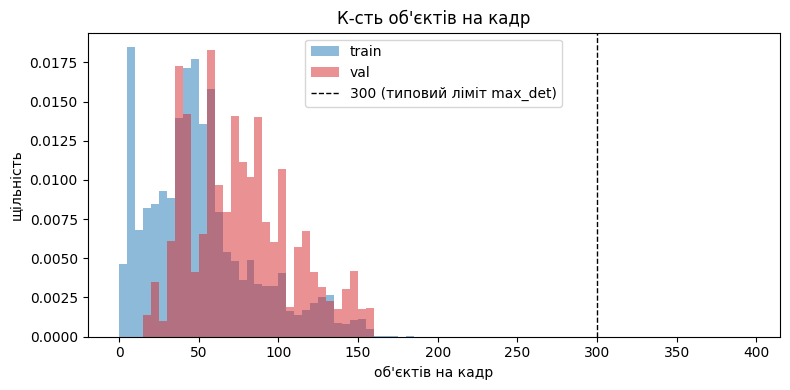

In [59]:
fig, ax = plt.subplots(figsize=(8, 4))
for s, c in [('train', 'tab:blue'), ('val', 'tab:red')]:
    ax.hist(per_frame.loc[per_frame.split == s, 'n'], bins=np.arange(0, 400, 5),
            density=True, alpha=.5, color=c, label=s)
ax.axvline(300, c='k', ls='--', lw=1, label='300 (типовий ліміт max_det)')
ax.set_xlabel('об\'єктів на кадр'); ax.set_ylabel('щільність')
ax.set_title('К-сть об\'єктів на кадр'); ax.legend()
plt.tight_layout(); plt.savefig('objects_per_frame.png', dpi=120); plt.show()

On average there are more objects on val per frame

val is denser, train розкиданіший



But this doesn`t include ignored regions -> it can be more densier.

### Describe how these vary across sequences

In [60]:
import matplotlib.pyplot as plt, seaborn as sns

# частка кожного класу в кожному кліпі
comp = obj.groupby(['video', 'cls']).size().unstack(fill_value=0)
comp.columns = CLASSES
comp_pct = comp.div(comp.sum(1), axis=0) * 100
split_of = imgs.drop_duplicates('video').set_index('video')['split']

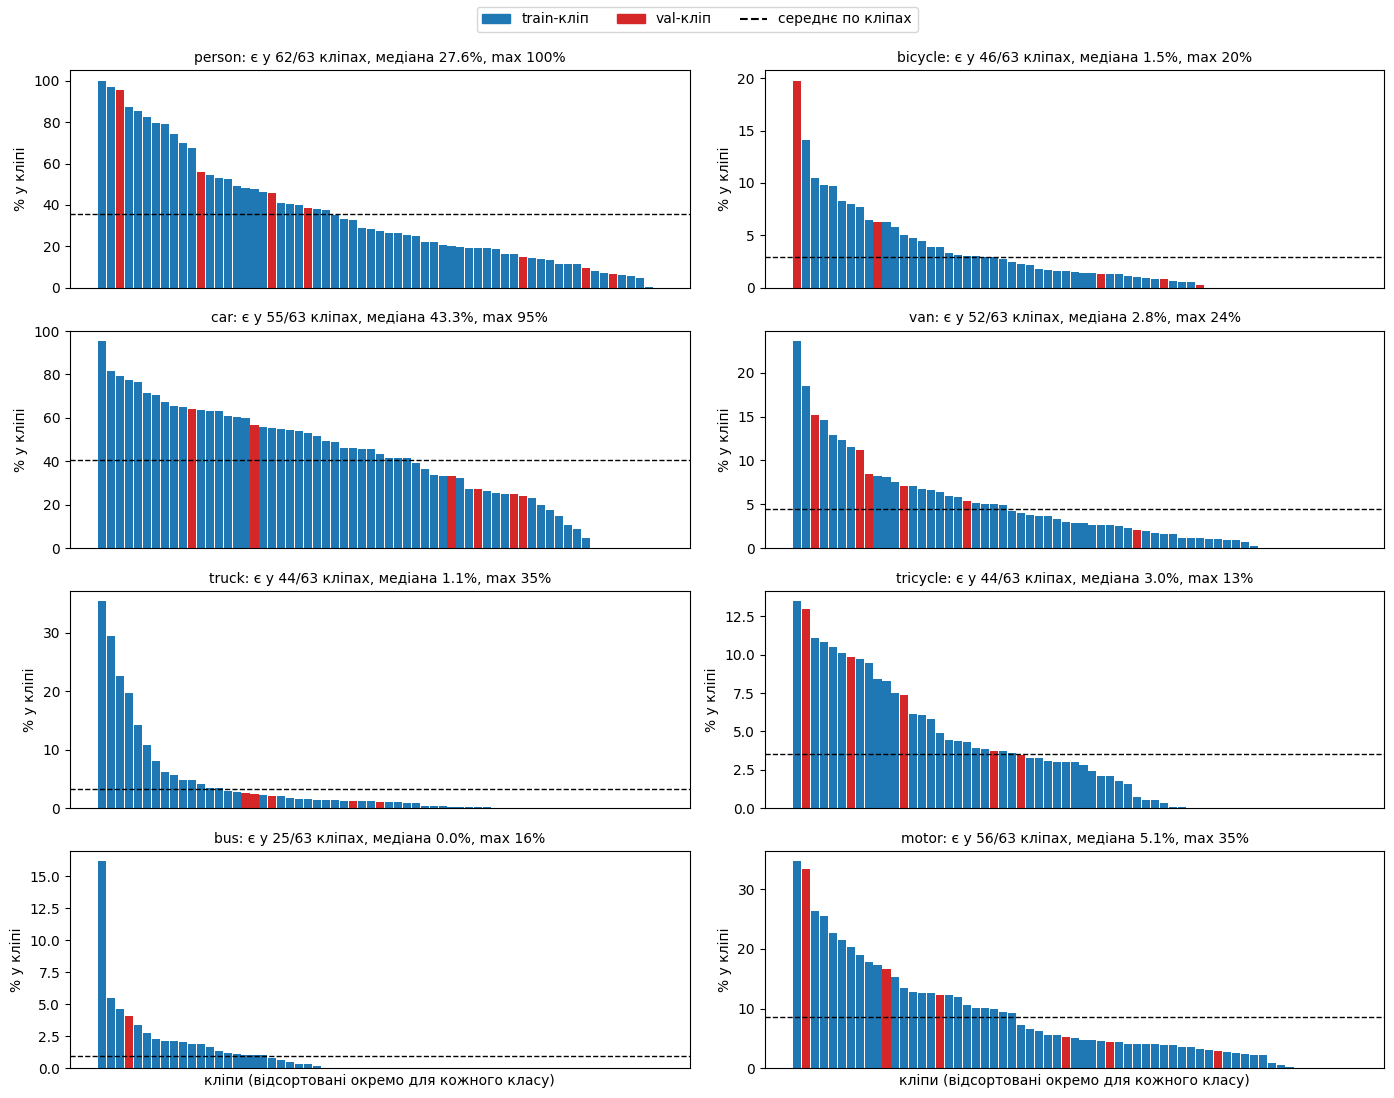

In [61]:
import matplotlib.pyplot as plt

# частка кожного класу в кожному кліпі, %
comp = obj.groupby(['video', 'cls']).size().unstack(fill_value=0)
comp.columns = CLASSES
comp_pct = comp.div(comp.sum(1), axis=0) * 100
split_of = imgs.drop_duplicates('video').set_index('video')['split']

fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for ax, c in zip(axes.flat, CLASSES):
    s = comp_pct[c].sort_values(ascending=False)        # кліпи від найбільшої частки до найменшої
    colors = ['tab:red' if split_of[v] == 'val' else 'tab:blue' for v in s.index]
    ax.bar(range(len(s)), s.values, color=colors, width=.9)
    ax.axhline(s.mean(), c='k', ls='--', lw=1)
    ax.set_title(f'{c}: є у {(s > 0).sum()}/{len(s)} кліпах, '
                 f'медіана {s.median():.1f}%, max {s.max():.0f}%', fontsize=10)
    ax.set_ylabel('% у кліпі')
for ax in axes[-1]:
    ax.set_xlabel('кліпи (відсортовані окремо для кожного класу)')
    ax.set_xticks([])
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='tab:blue'), plt.Rectangle((0, 0), 1, 1, color='tab:red'),
                    plt.Line2D([], [], c='k', ls='--')],
           labels=['train-кліп', 'val-кліп', 'середнє по кліпах'], loc='upper center', ncol=3)
plt.tight_layout(rect=[0, 0, 1, .97]); plt.savefig('cls_per_clip.png', dpi=120); plt.show()

1. Class composition depends heavily on the clip: car ranges from 0% to 95%, and motor and truck reach up to 35% in some clips.
2. Rare classes are concentrated in a few clips: bus appears in only 25/63 clips (median share 0%), truck and tricycle in 44/63.
3. Val clips are spread across the range for most classes, but for bus and truck they contain only small shares (≈1–4%), so AP for these classes on val will be based on few objects and will be noisy.


Медіанний розмір і медіанна к-сть об'єктів по кліпах

Розкид між кліпами (min / медіана / max медіан кліпів):
     size  density
min  24.5      5.0
50%  48.1     55.0
max  86.8    150.0


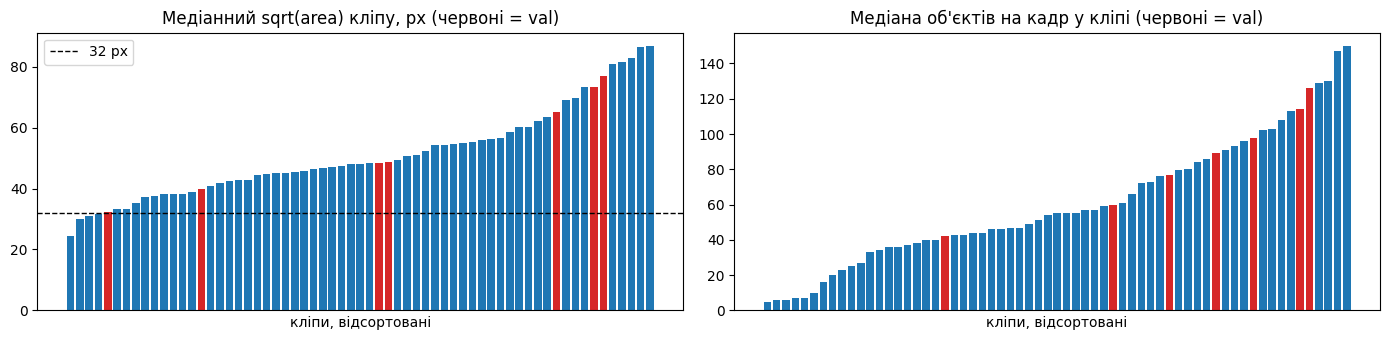

In [62]:
# медіани по кожному кліпу
clip_size = obj.groupby('video')['sqrt_area'].median()
clip_dens = per_frame.groupby('video')['n'].median()
clip_df = pd.DataFrame({'size': clip_size, 'density': clip_dens, 'split': split_of})

print('Розкид між кліпами (min / медіана / max медіан кліпів):')
print(clip_df[['size', 'density']].describe().loc[['min', '50%', 'max']].round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for a, col, title, ref in [(ax[0], 'size', 'Медіанний sqrt(area) кліпу, px', 32),
                           (ax[1], 'density', 'Медіана об\'єктів на кадр у кліпі', None)]:
    s = clip_df[col].sort_values()
    a.bar(range(len(s)), s.values, color=['tab:red' if clip_df.split[v] == 'val' else 'tab:blue' for v in s.index])
    if ref: a.axhline(ref, c='k', ls='--', lw=1, label='32 px')
    a.set_title(title + ' (червоні = val)'); a.set_xticks([]); a.set_xlabel('кліпи, відсортовані')
ax[0].legend()
plt.tight_layout(); plt.savefig('size_density_per_clip.png', dpi=120); plt.show()

1. Median object size per clip varies from 24.5 to 86.8 px
2. Median objects per frame varies about from 5 to 150
3. Val clips cover the size range well, but for density they are mainly in the middle-to-upper range.


Чи пов'язані розмір і щільність (кожна точка — кліп

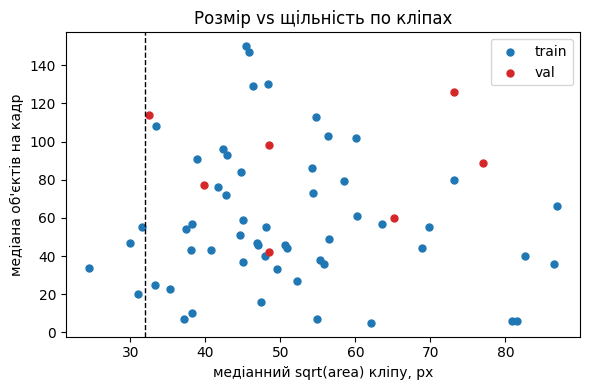

Кореляція Спірмена: 0.0


In [63]:
fig, ax = plt.subplots(figsize=(6, 4))
for s, c in [('train', 'tab:blue'), ('val', 'tab:red')]:
    d = clip_df[clip_df.split == s]
    ax.scatter(d['size'], d['density'], c=c, label=s, s=25)
ax.axvline(32, c='k', ls='--', lw=1)
ax.set_xlabel('медіанний sqrt(area) кліпу, px'); ax.set_ylabel('медіана об\'єктів на кадр')
ax.set_title('Розмір vs щільність по кліпах'); ax.legend()
plt.tight_layout(); plt.savefig('size_vs_density.png', dpi=120); plt.show()
print('Кореляція Спірмена:', clip_df['size'].corr(clip_df['density'], method='spearman').round(2))

There is no correlation between size and density -> size and density are independent across clips.

### Annotation format: ignored regions and non-target classes

COCO vs YOLO labels on pictures

YOLO-file: train/labels/uav0000295_02300_v/0000322.txt
['2 0.450184 0.334314 0.014338 0.026797', '7 0.170037 0.556209 0.012132 0.037908', '7 0.137500 0.547386 0.013235 0.030719']

Боксів: YOLO = 180, COCO = 180
Класи збігаються: True


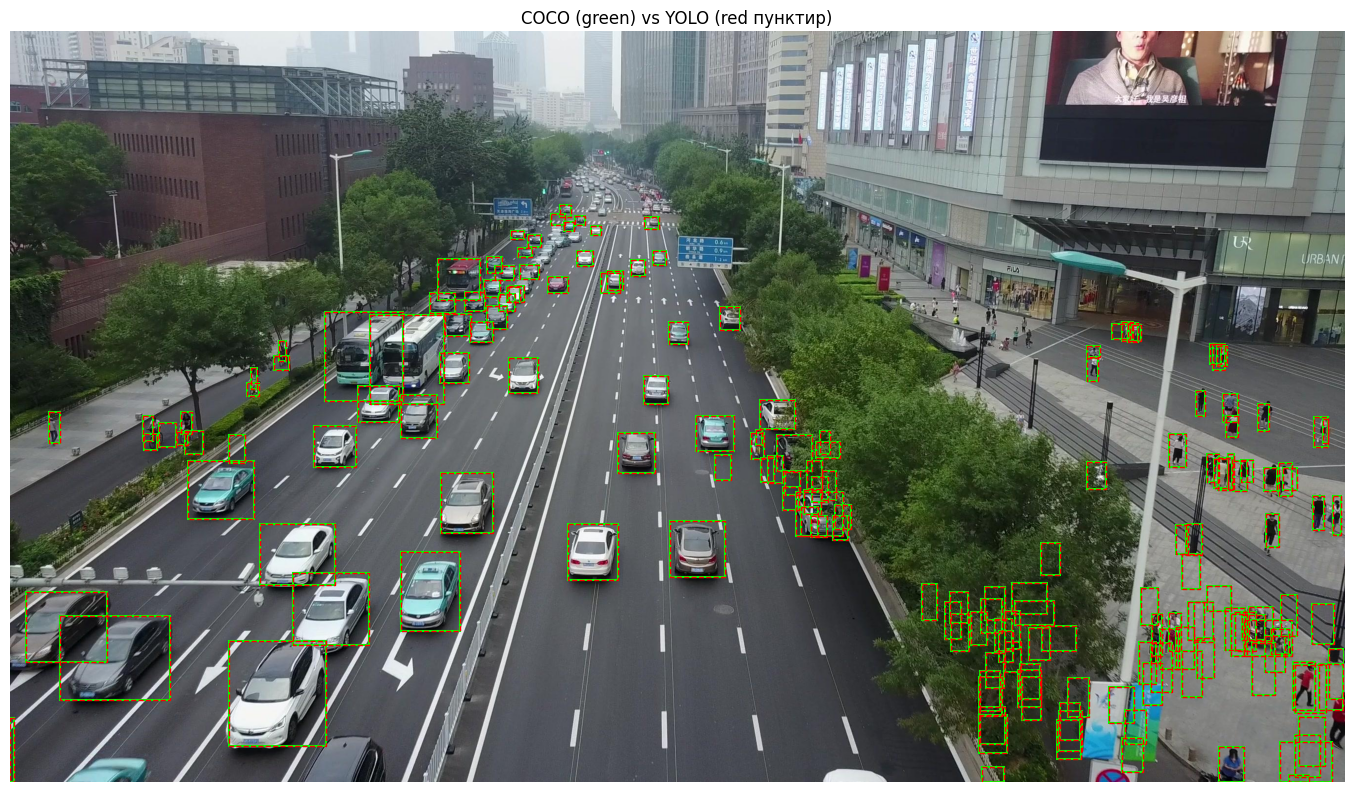

In [64]:
def read_yolo(path, W, H):
    """YOLO txt (cls cx cy w h, нормалізовано) -> DataFrame у пікселях (x, y = лівий верхній кут)."""
    if not path.exists() or path.stat().st_size == 0:
        return pd.DataFrame(columns=['cls', 'x', 'y', 'w', 'h'])
    a = np.loadtxt(path, ndmin=2)
    cls, cx, cy, w, h = a.T
    return pd.DataFrame({'cls': cls.astype(int), 'x': (cx - w/2) * W, 'y': (cy - h/2) * H,
                         'w': w * W, 'h': h * H})

info = imgs_tr[imgs_tr.image_id == dense_id].iloc[0]
lbl_path = ROOT / 'train' / info.file_name.replace('images/', 'labels/').replace('.jpg', '.txt')
yolo = read_yolo(lbl_path, info.width, info.height)
coco_b = anns_tr[(anns_tr.image_id == dense_id) & (anns_tr.iscrowd == 0)]

print('YOLO-file:', lbl_path.relative_to(ROOT))
print(open(lbl_path).read().splitlines()[:3])          # як виглядають сирі рядки
print(f'\nБоксів: YOLO = {len(yolo)}, COCO = {len(coco_b)}')
print('Класи збігаються:', sorted(yolo.cls) == sorted(coco_b.cls))

# COCO — green, YOLO — red
fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(Image.open(ROOT / 'train' / info.file_name))
for r in coco_b.itertuples():
    ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, ec='lime', lw=1.5))
for r in yolo.itertuples():
    ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, ec='red', lw=1, ls='--'))
ax.set_title('COCO (green) vs YOLO (red пунктир)'); ax.set_axis_off()
plt.tight_layout(); plt.savefig('coco_vs_yolo.png', dpi=120); plt.show()

Verify coco and yolo

In [65]:
def iou_matrix(a, b):
    """IoU між усіма парами боксів [x, y, w, h]: матриця len(a) x len(b)."""
    ax1, ay1, ax2, ay2 = a[:, 0], a[:, 1], a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx1, by1, bx2, by2 = b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2) - np.maximum(ax1[:, None], bx1), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2) - np.maximum(ay1[:, None], by1), 0, None)
    inter = iw * ih
    return inter / (a[:, 2:].prod(1)[:, None] + b[:, 2:].prod(1) - inter)

def check_split(split, im_df, an_df, n_frames=2000, seed=42):
    sample = im_df.sample(min(n_frames, len(im_df)), random_state=seed)
    by_img = an_df.groupby('image_id')
    rows = []
    for info in sample.itertuples():
        a = by_img.get_group(info.image_id) if info.image_id in by_img.groups else an_df.iloc[:0]
        coco_obj, coco_ign = a[a.iscrowd == 0], a[a.iscrowd == 1]
        base = info.file_name.replace('images/', '').replace('.jpg', '.txt')
        yolo = read_yolo(ROOT / split / 'labels' / base, info.width, info.height)
        ign_path = ROOT / split / 'ignore' / base
        n_ign_txt = len(np.loadtxt(ign_path, ndmin=2)) if ign_path.exists() and ign_path.stat().st_size else 0

        # найкращий IoU для кожного COCO-бокса серед YOLO-боксів того ж класу
        best = []
        for c in coco_obj.cls.unique():
            A = coco_obj.loc[coco_obj.cls == c, ['x', 'y', 'w', 'h']].values.astype(float)
            B = yolo.loc[yolo.cls == c, ['x', 'y', 'w', 'h']].values.astype(float)
            best.extend(iou_matrix(A, B).max(1) if len(B) else np.zeros(len(A)))
        rows.append({'n_coco': len(coco_obj), 'n_yolo': len(yolo),
                     'n_ign_coco': len(coco_ign), 'n_ign_txt': n_ign_txt,
                     'min_iou': min(best) if best else 1.0})
    r = pd.DataFrame(rows)
    print(f'{split}: перевірено {len(r)} кадрів')
    print(f'  к-сть об\'єктів збігається:  {(r.n_coco == r.n_yolo).mean():.1%} кадрів')
    print(f'  к-сть ignore збігається:    {(r.n_ign_coco == r.n_ign_txt).mean():.1%} кадрів')
    print(f'  мінімальний IoU COCO↔YOLO:  {r.min_iou.min():.4f}')
    print(f'  кадрів з IoU < 0.99:        {(r.min_iou < .99).sum()}')
    return r

res_tr = check_split('train', imgs_tr, anns_tr)
res_va = check_split('val', imgs_va, anns_va, n_frames=len(imgs_va))   # val перевіряємо повністю

train: перевірено 2000 кадрів
  к-сть об'єктів збігається:  100.0% кадрів
  к-сть ignore збігається:    25.2% кадрів
  мінімальний IoU COCO↔YOLO:  0.9996
  кадрів з IoU < 0.99:        0
val: перевірено 2846 кадрів
  к-сть об'єктів збігається:  100.0% кадрів
  к-сть ignore збігається:    49.6% кадрів
  мінімальний IoU COCO↔YOLO:  0.9996
  кадрів з IoU < 0.99:        0


#### Diagnotic of ignore

Ignore is written in two places - iscrowd=1 and ignore/*.txt-> there number of ignore is different -> check which to use

In [66]:
bad = res_tr[res_tr.n_ign_coco != res_tr.n_ign_txt]
print(bad[['n_ign_coco', 'n_ign_txt']].describe().round(1))
print('\nКадрів, де txt = 0, а в COCO > 0:', ((bad.n_ign_txt == 0) & (bad.n_ign_coco > 0)).sum(), 'з', len(bad))
print('Різниця COCO − txt:', (bad.n_ign_coco - bad.n_ign_txt).describe().round(1).to_dict())

info = imgs_tr[imgs_tr.image_id == dense_id].iloc[0]
base = info.file_name.replace('images/', '').replace('.jpg', '.txt')
p = ROOT / 'train' / 'ignore' / base
print('\nШлях:', p, '| існує:', p.exists())
if p.exists():
    print('рядків у txt:', len(open(p).read().splitlines()))
print('iscrowd у COCO:', ((anns_tr.image_id == dense_id) & (anns_tr.iscrowd == 1)).sum())
print('Значення orig_category_id серед iscrowd:', anns_tr.loc[anns_tr.iscrowd == 1, 'orig_category_id'].value_counts().to_dict())

       n_ign_coco  n_ign_txt
count      1496.0     1496.0
mean         28.7        3.6
std          26.6        3.3
min           8.0        1.0
25%           8.0        1.0
50%          16.0        2.0
75%          40.0        5.0
max         168.0       21.0

Кадрів, де txt = 0, а в COCO > 0: 0 з 1496
Різниця COCO − txt: {'count': 1496.0, 'mean': 25.1, 'std': 23.3, 'min': 7.0, '25%': 7.0, '50%': 14.0, '75%': 35.0, 'max': 147.0}

Шлях: /content/data/train/ignore/uav0000295_02300_v/0000322.txt | існує: True
рядків у txt: 9
iscrowd у COCO: 72
Значення orig_category_id серед iscrowd: {0: 498952, 11: 11792}


Its just that in coco it is written 8 times, 1 time per class, and in txt - one time.-> data is thr same just in different formats

In [67]:
ig = anns_tr[anns_tr.iscrowd == 1]
per_box = ig.groupby(['image_id', 'x', 'y', 'w', 'h'])['category_id'].agg(['count', 'nunique'])
print('Скільки разів повторюється кожна зона:', per_box['count'].value_counts().to_dict())
print('Унікальних ignored regions у train:', len(per_box), '(а не', len(ig), ')')

Скільки разів повторюється кожна зона: {8: 63843}
Унікальних ignored regions у train: 63843 (а не 510744 )


### original VisDrone classes -> 8 target classes

1. pedestrian+people-> person
2. tricycle + awning-tricycle → tricycle
3. other-> ignored (as not target class, not deleted, detentions are not fined on them)

In [68]:
VISDRONE = {0: 'ignored region', 1: 'pedestrian', 2: 'people', 3: 'bicycle', 4: 'car', 5: 'van',
            6: 'truck', 7: 'tricycle', 8: 'awning-tricycle', 9: 'bus', 10: 'motor', 11: 'others'}

m = anns_tr.copy()
m['orig'] = m['orig_category_id'].map(VISDRONE)
m['ours'] = np.where(m['iscrowd'] == 1, 'IGNORED', m['cls'].map(dict(enumerate(CLASSES))))
print(pd.crosstab(m['orig'], m['ours']))

ours             IGNORED  bicycle   bus     car   motor  person  tricycle  \
orig                                                                        
awning-tricycle        0        0     0       0       0       0     13011   
bicycle                0    40255     0       0       0       0         0   
bus                    0        0  9653       0       0       0         0   
car                    0        0     0  505301       0       0         0   
ignored region    498952        0     0       0       0       0         0   
motor                  0        0     0       0  102819       0         0   
others             11792        0     0       0       0       0         0   
pedestrian             0        0     0       0       0  234305         0   
people                 0        0     0       0       0   94396         0   
tricycle               0        0     0       0       0       0     28338   
truck                  0        0     0       0       0       0         0   

### Train / validation split
We use the provided split (56 train clips, 7 val clips) as a fixed hold-out for all models.

Check that no clip, and no original video (prefix before `_`, e.g. `uav0000013`), appears in both train and val.

In [69]:
clips_tr = set(imgs_tr['video'])
clips_va = set(imgs_va['video'])
print('Спільних кліпів train/val:', clips_tr & clips_va)


base = lambda v: v.split('_')[0]
base_tr = {base(v) for v in clips_tr}
base_va = {base(v) for v in clips_va}
shared = base_tr & base_va
print(f'\nОригінальних відео: train {len(base_tr)}, val {len(base_va)}')
print('Відео, фрагменти яких є і в train, і у val:', shared)
for b in shared:
    print(f'  {b}: train {sorted(v for v in clips_tr if base(v) == b)} | val {sorted(v for v in clips_va if base(v) == b)}')

Спільних кліпів train/val: set()

Оригінальних відео: train 48, val 7
Відео, фрагменти яких є і в train, і у val: set()


no data leakage!

### Frame subsampling
Consecutive frames are highly redundant and make training very long. For each object (`track_id`) we check whether it is still present k frames later and how much its box moved (IoU with itself). Low change at step k means frames k apart carry almost the same information, so we can train on every k-th frame.

    objects still present, %  median IoU with itself  IoU < 0.5, %  \
k                                                                    
1                      99.29                    0.90          4.10   
2                      98.60                    0.81         13.94   
5                      96.57                    0.60         40.52   
10                     93.27                    0.36         60.61   
20                     87.00                    0.10         73.88   
50                     70.54                    0.00         82.57   

    train frames at step k  
k                           
1                    24201  
2                    12100  
5                     4840  
10                    2420  
20                    1210  
50                     484  


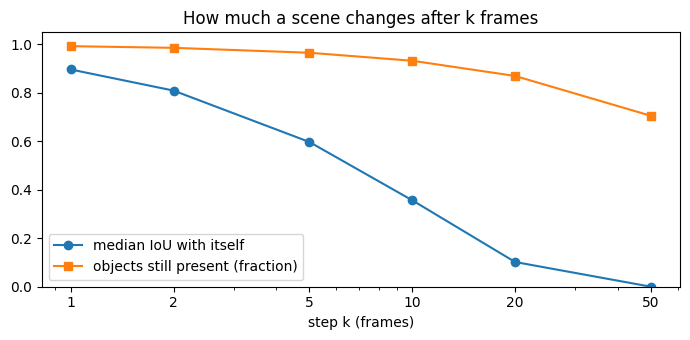

In [70]:
def box_iou(a, b):
    """IoU між відповідними боксами [x, y, w, h] (попарно, рядок до рядка)."""
    x1 = np.maximum(a[:, 0], b[:, 0]); y1 = np.maximum(a[:, 1], b[:, 1])
    x2 = np.minimum(a[:, 0] + a[:, 2], b[:, 0] + b[:, 2]); y2 = np.minimum(a[:, 1] + a[:, 3], b[:, 1] + b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / (a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter)

t = obj[obj.split == 'train'].merge(imgs_tr[['image_id', 'frame_id']], on='image_id')
t = t[['video', 'track_id', 'frame_id', 'x', 'y', 'w', 'h']]
rows = []
for k in [1, 2, 5, 10, 20, 50]:
    m = t.merge(t.assign(frame_id=t.frame_id - k), on=['video', 'track_id', 'frame_id'], suffixes=('', '_k'))
    iou = box_iou(m[['x', 'y', 'w', 'h']].values, m[['x_k', 'y_k', 'w_k', 'h_k']].values)
    rows.append({'k': k,
                 'objects still present, %': len(m) / len(t) * 100,
                 'median IoU with itself': np.median(iou),
                 'IoU < 0.5, %': (iou < .5).mean() * 100,
                 'train frames at step k': len(imgs_tr) // k})
sub = pd.DataFrame(rows).set_index('k')
print(sub.round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(sub.index, sub['median IoU with itself'], 'o-', label='median IoU with itself')
ax.plot(sub.index, sub['objects still present, %'] / 100, 's-', label='objects still present (fraction)')
ax.set_xscale('log'); ax.set_xticks(sub.index, sub.index)
ax.set_xlabel('step k (frames)'); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title('How much a scene changes after k frames')
plt.tight_layout(); plt.savefig('subsampling.png', dpi=120); plt.show()

We choose k=5 as median IoU is 0.6 -> its not dublicates and objects are the same - 96%. Number of frames to train is in 5 times less than without subsampling

#### Observations that inform later choices
1. **Input resolution: 1280** (When imgsz=640 54% of objects are < 16 px, 1280- only  ~10%)
2. **Augmentation: scale-augmentation** (test frames are smaller than train(680–1920 px)-> when we train model will see the same object in different sizes and better perform on test)
3. **Model: multi-scale / FPN** (size of objects 24-87px between clips, inside class spread is even bigger -> model look for object on several maps of different level of detail)
4. **Anchors: aspect ratios ~0.5–2**(person h/w = 2.0, car 0.79, o†her ~1-> sizes for anchors will choose later)
5. **Loss / sampling: focal loss, per-class AP, maybe copy-paste** (imbalance of classes in 50 times, bus in only in 25/63 clips)
6. **max_det / queries: 300 si enough**(max 180 objects per frame)
7. **Split by clips**(by frame would be data leakage, clips are very different, val is densier)
8. **Normalization:** YOLO models scale pixels to [0, 1]; torchvision models use ImageNet mean/std because they start from ImageNet-pretrained weights.
9. **Reproducibility:** all settings are fixed in `CFG`, the random seed is 42, and frame subsampling is deterministic (every 5th frame of each clip), so the same dataset is built on every run.

### Preprocessing: building the training dataset
Every 5th frame is taken from each clip. Ignored regions are filled with grey (114) so the model does not learn crowds and parking lots as background, and labels covered by an ignored region by ≥50% are removed. Frames are downscaled to 1280 px on the longer side (YOLO labels are normalised, so they stay valid). The result is saved in Ultralytics format with a `data.yaml`. Final metrics are computed with pycocotools on the original val frames, where ignored regions are handled by `iscrowd=1`.

In [71]:
import cv2
from concurrent.futures import ThreadPoolExecutor

K = 5            # крок субсемплінгу
IMGSZ = 1280     # довша сторона збереженого кадру
FILL = 114       # сірий колір для ignored regions
MAX_COVER = 0.5  # бокс, закритий ignore більш ніж на 50%, прибираємо з міток
OUT = Path('/content/prepared')

def subsample(im_df, k):
    """Кожен k-й кадр у кожному кліпі (детерміновано)."""
    df = im_df.sort_values(['video', 'frame_id'])
    return df[df.groupby('video').cumcount() % k == 0]

def read_txt(p, ncol):
    if not p.exists() or p.stat().st_size == 0:
        return np.zeros((0, ncol))
    return np.loadtxt(p, ndmin=2)

def prepare_frame(split, file_name):
    rel = file_name.replace('images/', '')                      # clip/frame.jpg
    img = cv2.imread(str(ROOT / split / file_name))
    H, W = img.shape[:2]
    lbl = read_txt(ROOT / split / 'labels' / rel.replace('.jpg', '.txt'), 5)
    ign = read_txt(ROOT / split / 'ignore' / rel.replace('.jpg', '.txt'), 4)
    dropped = 0
    if len(ign):
        # ignored regions -> пікселі [x1, y1, x2, y2], зафарбовуємо сірим
        cx, cy, w, h = ign.T
        ig = np.stack([(cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H], 1)
        for x1, y1, x2, y2 in np.clip(ig.round(), 0, None).astype(int):
            img[y1:y2, x1:x2] = FILL
        # прибираємо мітки об'єктів, які майже повністю опинились під сірим
        if len(lbl):
            c, bx, by, bw, bh = lbl.T
            b = np.stack([(bx - bw/2) * W, (by - bh/2) * H, (bx + bw/2) * W, (by + bh/2) * H], 1)
            iw = np.clip(np.minimum(b[:, None, 2], ig[None, :, 2]) - np.maximum(b[:, None, 0], ig[None, :, 0]), 0, None)
            ih = np.clip(np.minimum(b[:, None, 3], ig[None, :, 3]) - np.maximum(b[:, None, 1], ig[None, :, 1]), 0, None)
            cover = (iw * ih).max(1) / ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))
            dropped = int((cover >= MAX_COVER).sum())
            lbl = lbl[cover < MAX_COVER]
    # зменшуємо до IMGSZ по довшій стороні
    s = min(IMGSZ / max(H, W), 1)
    if s < 1:
        img = cv2.resize(img, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA)
    dst = OUT / split / 'images' / rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(dst), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
    ldst = OUT / split / 'labels' / rel.replace('.jpg', '.txt')
    ldst.parent.mkdir(parents=True, exist_ok=True)
    np.savetxt(ldst, lbl, fmt='%d %.6f %.6f %.6f %.6f')
    return len(lbl), dropped

for split, im_df in [('train', imgs_tr), ('val', imgs_va)]:
    sub = subsample(im_df, K)
    with ThreadPoolExecutor(8) as ex:
        res = np.array(list(ex.map(lambda f: prepare_frame(split, f), sub['file_name'])))
    print(f'{split}: {len(sub)} кадрів, {res[:, 0].sum()} об\'єктів, прибрано під ignore: {res[:, 1].sum()}')

(OUT / 'data.yaml').write_text(
    f"path: {OUT}\ntrain: train/images\nval: val/images\nnc: {len(CLASSES)}\nnames: {CLASSES}\n")
print(open(OUT / 'data.yaml').read())

train: 4868 кадрів, 220337 об'єктів, прибрано під ignore: 2542
val: 571 кадрів, 22650 об'єктів, прибрано під ignore: 256
path: /content/prepared
train: train/images
val: val/images
nc: 8
names: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']



masking almost doesnt catch real objects: only ~1% of label are below grey.

#### Check: one frame before and after preprocessing

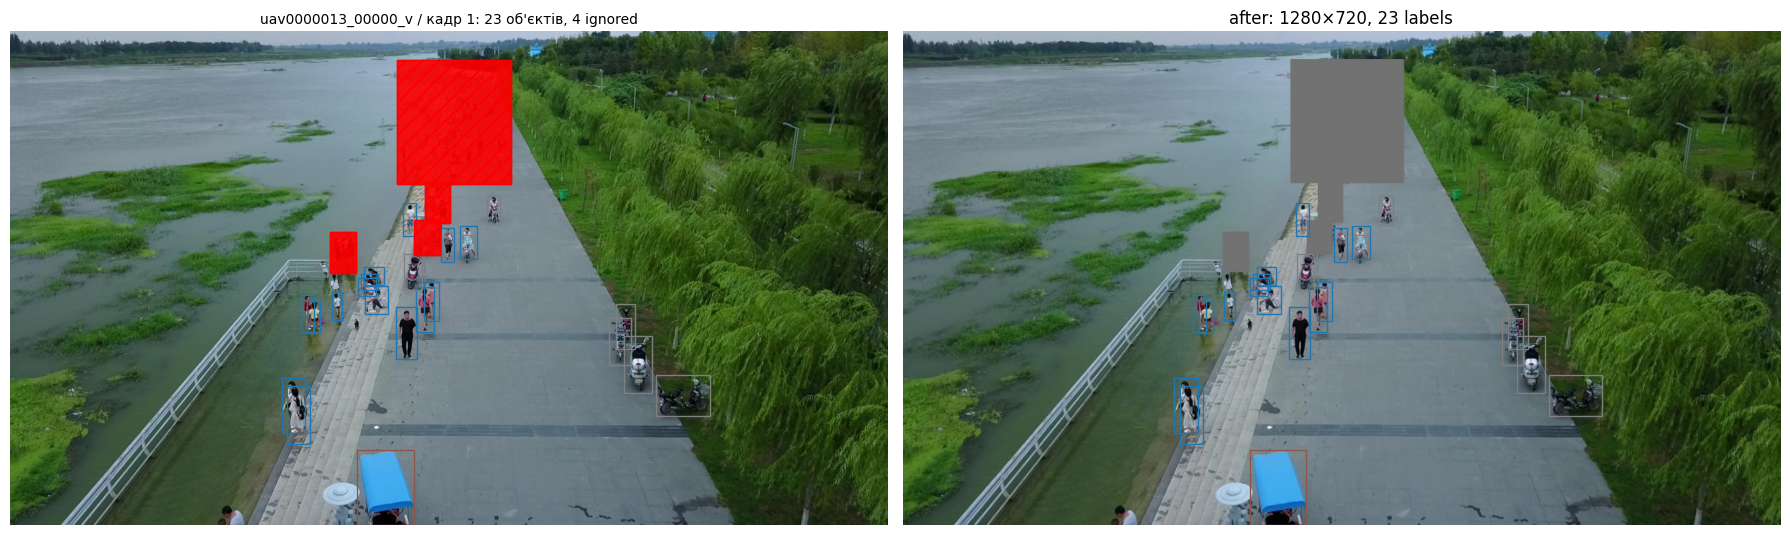

In [80]:
ex = subsample(imgs_tr, K)
ex = ex[ex.image_id.isin(anns_tr.loc[anns_tr.iscrowd == 1, 'image_id'])].iloc[0]   # кадр, де є ignore
rel = ex.file_name.replace('images/', '')
prep = cv2.cvtColor(cv2.imread(str(OUT / 'train/images' / rel)), cv2.COLOR_BGR2RGB)
lab = read_txt(OUT / 'train/labels' / rel.replace('.jpg', '.txt'), 5)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
show_frame(ex.image_id, ax=axes[0])
axes[1].imshow(prep)
h, w = prep.shape[:2]
for c, cx, cy, bw, bh in lab:
    axes[1].add_patch(patches.Rectangle(((cx - bw/2) * w, (cy - bh/2) * h), bw * w, bh * h,
                                        fill=False, lw=1, ec=COLORS[int(c)]))
axes[1].set_title(f'after: {w}×{h}, {len(lab)} labels'); axes[1].set_axis_off()
plt.tight_layout(); plt.savefig('preprocessing_example.png', dpi=120); plt.show()

#### Resizing, normalization and augmentation (shared by all models)
All settings are fixed in one config so every model is trained under the same protocol and results are reproducible.

In [73]:
CFG = {
    'seed': 42,
    'frame_step': 5,
    # resizing
    'imgsz': 1280,                 # довша сторона; коротша доповнюється сірим (letterbox), пропорції зберігаються
    # normalization
    'yolo_norm': 'pixels / 255',
    'torchvision_norm': {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]},  # ImageNet, бо ваги pretrained
    # augmentation (Ultralytics)
    'fliplr': 0.5,                 # горизонтальний фліп
    'scale': 0.5,                  # випадковий масштаб ±50% (різні розміри кадрів у train і test)
    'translate': 0.1,
    'mosaic': 1.0, 'close_mosaic': 10,   # mosaic вимикається на останніх 10 епохах
    'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4,   # колір і яскравість (різне освітлення, день/ніч)
}
import json; print(json.dumps(CFG, indent=2))

{
  "seed": 42,
  "frame_step": 5,
  "imgsz": 1280,
  "yolo_norm": "pixels / 255",
  "torchvision_norm": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  },
  "fliplr": 0.5,
  "scale": 0.5,
  "translate": 0.1,
  "mosaic": 1.0,
  "close_mosaic": 10,
  "hsv_h": 0.015,
  "hsv_s": 0.7,
  "hsv_v": 0.4
}


In [74]:
from google.colab import drive
drive.mount('/content/drive')
!cd /content && zip -qr /content/drive/MyDrive/hw2_prepared.zip prepared
!ls -lh /content/drive/MyDrive/hw2_prepared.zip

Mounted at /content/drive
-rw------- 1 root root 1.7G Nov  7 11:06 /content/drive/MyDrive/hw2_prepared.zip
